# Analisis Univariante

In [1]:
import pandas as pd
import numpy as np
import seaborn  as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import pyarrow
import sys
import json

sys.path.insert(0, "../utils")
import importlib
import utils
importlib.reload(utils)

<module 'utils' from '/Users/amber/LocalDrive/Bootcamp Data Science/DS-EDA/src/notebooks/../utils/utils.py'>

In [2]:
df = pd.read_parquet("../data/juegos_steam.parquet")

In [3]:
# Cardinalidad y tipo de cada variable

df_cardinalidad = pd.DataFrame([df.nunique(), df.nunique()/len(df) * 100, df.dtypes]).T.rename(columns = {0: "Card",\
                                                                                                    1: "%_Card", 2: "Tipo"})
df_cardinalidad

,Card,%_Card,Tipo
release_date,1094,2.624949,datetime64[us]
estimated_owners,23,0.055186,str
genres,1613,3.87024,string
estimated_owners_min,12,0.028793,int64
estimated_owners_max,12,0.028793,int64
genre_0,23,0.055186,str
genre_1,23,0.055186,str
genre_2,22,0.052787,str
genre_3,21,0.050388,str
genre_4,20,0.047988,str


In [4]:
df.release_date.unique()

<DatetimeArray>
['2024-06-06 00:00:00', '2024-08-15 00:00:00', '2023-10-20 00:00:00',
 '2023-08-08 00:00:00', '2024-05-20 00:00:00', '2023-12-22 00:00:00',
 '2023-11-09 00:00:00', '2024-02-21 00:00:00', '2025-04-16 00:00:00',
 '2024-03-15 00:00:00',
 ...
 '2023-06-11 00:00:00', '2023-03-26 00:00:00', '2023-04-15 00:00:00',
 '2023-01-29 00:00:00', '2023-02-18 00:00:00', '2023-05-07 00:00:00',
 '2023-02-05 00:00:00', '2023-04-22 00:00:00', '2023-05-13 00:00:00',
 '2023-04-23 00:00:00']
Length: 1094, dtype: datetime64[us]

In [5]:
df.genres.unique()

<ArrowStringArray>
[                                                                                                                                                                                                                                                                               '["Casual", "Indie", "Racing"]',
                                                                                                                                                                                                                                                                             '["Action", "Adventure", "Indie"]',
                                                                                                                                                                                                                                                         '["Action", "Casual", "Indie", "RPG", "Early Access"]',
                                                                  

En nuestro caso, en nuestro analisis, las columnas target son "generos", "estimated_owners_min", "estimated_owners_max" y "month"

In [6]:
# Vamos a pasar a lista las variables categoricas

categoricas_generos = []

for i in range(11):
    categoricas_generos.append("genre_" + str(i))

In [7]:
# Frecuencias absolutas

for columna in categoricas_generos:
    print(df[columna].value_counts(), "\n")

genre_0
Action                   16435
Casual                    9212
Adventure                 9023
Indie                     4115
Simulation                 892
RPG                        767
Strategy                   579
Racing                     185
Utilities                   78
Animation & Modeling        73
Sports                      62
Free To Play                53
Design & Illustration       46
Desconocido                 42
Massively Multiplayer       38
Audio Production            23
Education                   18
Early Access                10
Video Production            10
Photo Editing                8
Game Development             4
Software Training            3
Accounting                   1
Name: count, dtype: int64 

genre_1
Indie                    13476
Adventure                 8069
Casual                    6981
Desconocido               6016
Simulation                2081
RPG                       1844
Strategy                  1477
Early Access              

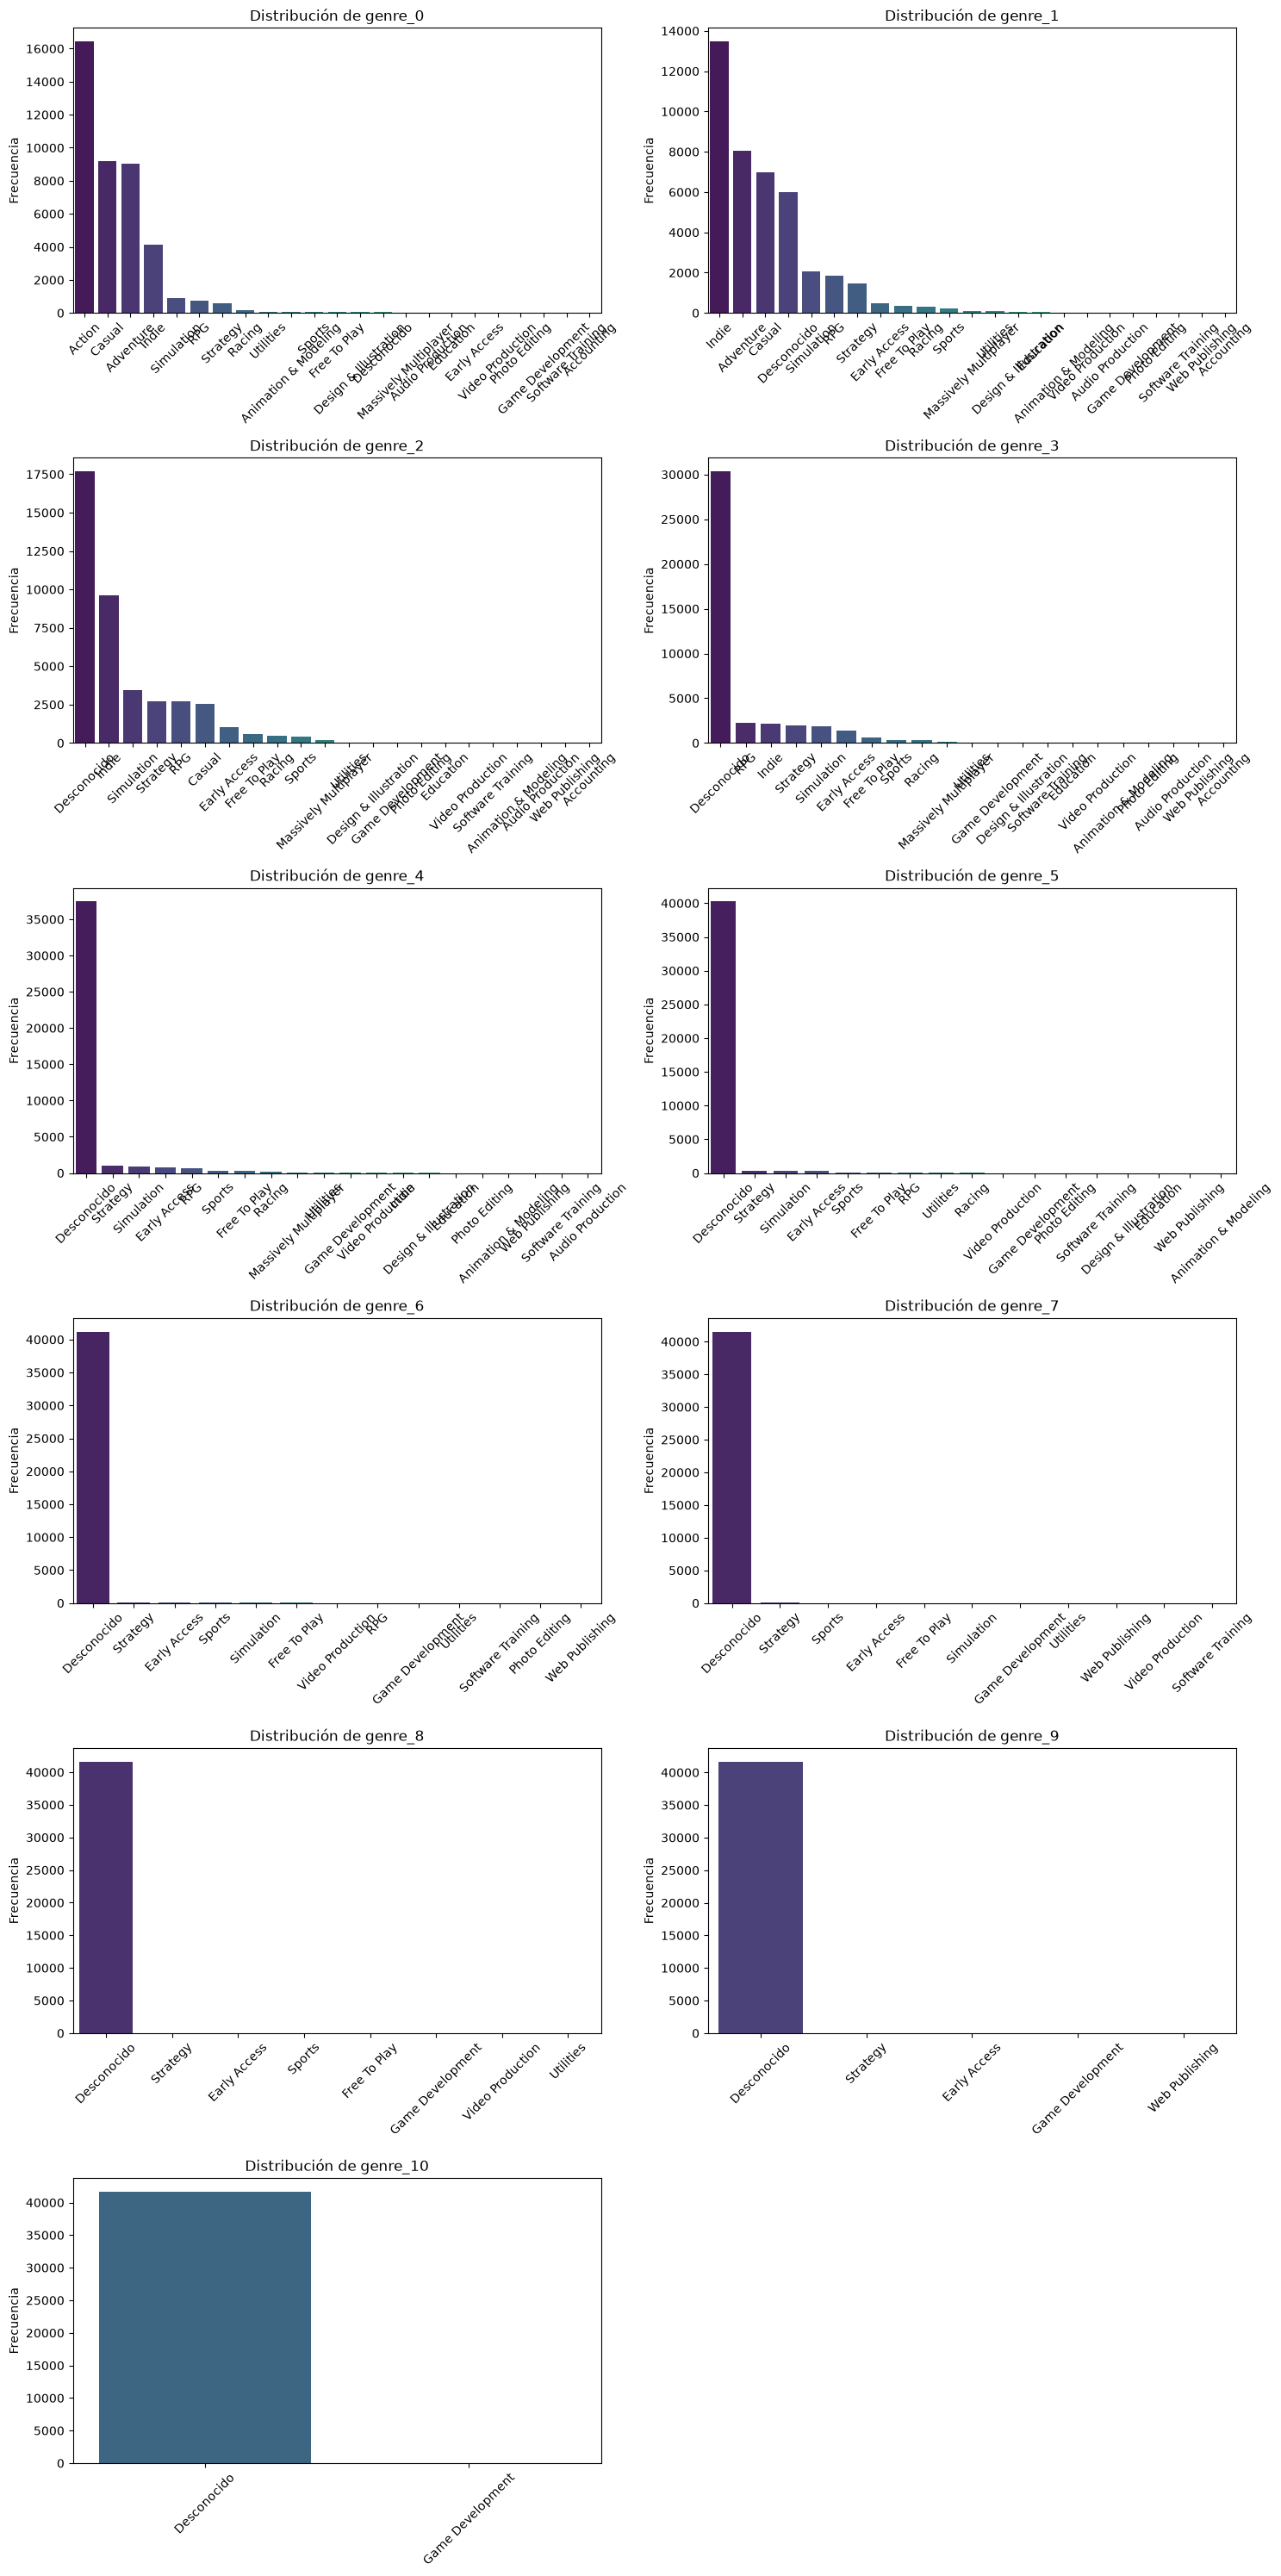

In [8]:
utils.pinta_distribucion_categoricas(df, categoricas_generos)

Esto nos da a entender, que la gran mayoria de juegos tienen como mucho 1-2 generos 

### Ahora vamos a ver las tendencias

In [9]:
# Primero las medias
df.describe().loc["mean"]

release_date            2024-07-29 03:11:39.407347
estimated_owners_min                  21697.818941
estimated_owners_max                  65276.051539
month                                     6.556206
Name: mean, dtype: object

In [10]:
df.describe().loc["max"]

release_date            2025-12-31 00:00:00
estimated_owners_min             50000000.0
estimated_owners_max            100000000.0
month                                  12.0
Name: max, dtype: object

In [11]:
# Ahora las medianas
df.describe().loc["50%"]

release_date            2024-08-21 00:00:00
estimated_owners_min                    0.0
estimated_owners_max                20000.0
month                                   7.0
Name: 50%, dtype: object

In [12]:
# Y la moda de los generos
df[categoricas_generos].mode().T

,0
genre_0,Action
genre_1,Indie
genre_2,Desconocido
genre_3,Desconocido
genre_4,Desconocido
genre_5,Desconocido
genre_6,Desconocido
genre_7,Desconocido
genre_8,Desconocido
genre_9,Desconocido


In [13]:
IQR_mes = utils.sacar_IQR(df, "month")
IQR_owners_min = utils.sacar_IQR(df, "estimated_owners_min")
IQR_owners_max = utils.sacar_IQR(df, "estimated_owners_max")

print("IQR_mes", IQR_mes)
print("IQR_owners_min", IQR_owners_min)
print("IQR_owners_max", IQR_owners_max)


IQR_mes 6.0
IQR_owners_min 0.0
IQR_owners_max 0.0


In [14]:
df.describe().loc["max"] - df.describe().loc["min"]

release_date            1095 days 00:00:00
estimated_owners_min            50000000.0
estimated_owners_max            99980000.0
month                                 11.0
dtype: object

<Axes: title={'center': 'Juegos por mes'}, xlabel='month', ylabel='Cantidad'>

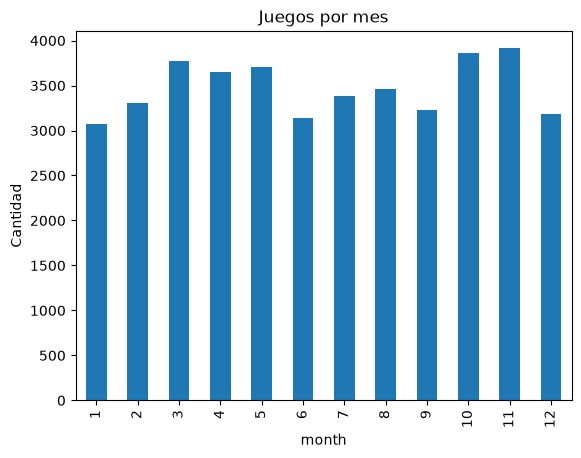

In [15]:
df["month"].value_counts().sort_index().plot(kind="bar", title="Juegos por mes", ylabel="Cantidad")

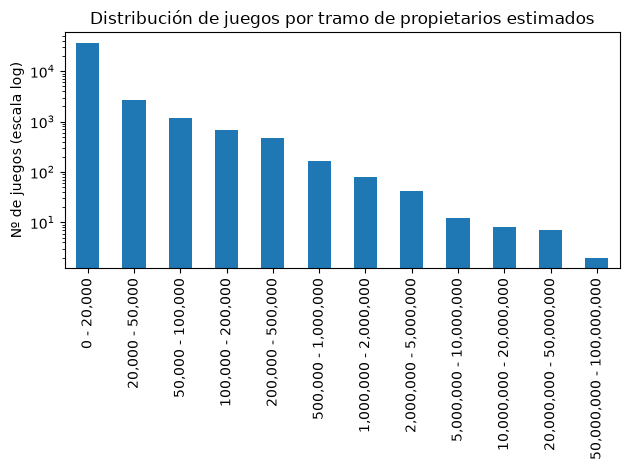

In [16]:
conteo = df.groupby(["estimated_owners_min", "estimated_owners_max"]).size()
conteo.index = [f"{a:,} - {b:,}" for a, b in conteo.index]

conteo.plot(kind="bar", logy=True)
plt.ylabel("Nº de juegos (escala log)")
plt.title("Distribución de juegos por tramo de propietarios estimados")
plt.tight_layout()
plt.show()